# Bagian B – SigLIP Embedding Probe (Ekstrak Sekali → Train Head Cepat)

**Checkpoint:** `google/siglip-so400m-patch14-384`

## Alur (2 tahap)

```
TAHAP 1 – dijalankan SEKALI (lambat, butuh GPU)
  gambar → [augmentasi] → SigLIP (dibekukan, fp16) → embedding 1152-dim → embeddings_{split}.npz  (di Drive)

TAHAP 2 – bisa diulang berkali-kali (hitungan detik/menit per run)
  embeddings_{split}.npz → load → train head → evaluasi
  (ganti/bandingkan arsitektur: linear, MLP, MLP+norm, MLP 2 tahap, ResMLP, kNN, SVM, LightGBM, ensemble)
```

Kenapa lebih cepat dari notebook sebelumnya: di notebook lama, **setiap epoch** semua gambar dibaca ulang,
diaugmentasi, lalu dilewatkan ke backbone SigLIP (~400M parameter) walaupun backbone dibekukan. Di sini backbone
hanya dipakai **satu kali per gambar**; training head bekerja di atas vektor 1152-dim yang sudah tersimpan.

**Prasyarat:** sudah menjalankan preprocessing (`train.csv`, `val.csv`, `test.csv`, `class_weights.json`) dan upload ke Google Drive.


---
## CELL 1 – Mount Google Drive


In [1]:
from google.colab import drive
drive.mount('/content/drive', force_remount=False)
print('[OK] Google Drive berhasil di-mount.')


Mounted at /content/drive
[OK] Google Drive berhasil di-mount.


---
## CELL 2 – Konfigurasi Utama


In [2]:
import os

# ============================================================
# KONFIGURASI – sesuaikan ROOT_DIR dengan lokasi upload Anda
# ============================================================
ROOT_DIR    = '/content/drive/MyDrive/Senpro'
DATASET_DIR = os.path.join(ROOT_DIR, 'Dataset')
OUTPUT_DIR  = os.path.join(ROOT_DIR, 'preprocessing_output')

TRAIN_CSV = os.path.join(OUTPUT_DIR, 'train.csv')
VAL_CSV   = os.path.join(OUTPUT_DIR, 'val.csv')
TEST_CSV  = os.path.join(OUTPUT_DIR, 'test.csv')
CW_JSON   = os.path.join(OUTPUT_DIR, 'class_weights.json')

# Label mapping (sama seperti notebook sebelumnya)
LABEL_TO_IDX = {'Recylable': 0, 'Organik': 1, 'B3': 2}
IDX_TO_LABEL = {v: k for k, v in LABEL_TO_IDX.items()}
NUM_CLASSES  = len(LABEL_TO_IDX)

RANDOM_SEED = 42

# ------------------------------------------------------------
# TAHAP 1 – Ekstraksi embedding (SigLIP, dijalankan sekali)
# ------------------------------------------------------------
MODEL_CHECKPOINT = 'google/siglip-so400m-patch14-384'
IMAGE_SIZE       = 384

N_AUG = 2                    # jumlah versi TER-AUGMENTASI per gambar train (di luar versi asli)
                             # total baris train di .npz = jumlah_gambar x (1 + N_AUG). Set 0 = tanpa augmentasi.
BATCH_SIZE_EKSTRAKSI = 32    # jumlah gambar per batch (tiap gambar diproses (1 + N_AUG) view). Turunkan jika OOM.
NUM_WORKERS_EKSTRAKSI = min(8, (os.cpu_count() or 2) * 2)   # Colab gratis biasanya 2 CPU -> 4 worker
USE_FP16         = True      # backbone dijalankan fp16 (lebih cepat & hemat VRAM), hanya untuk ekstraksi
MAX_SISI_GAMBAR  = 1024      # gambar lebih besar dari ini di-downsize dulu (hemat RAM/CPU)
CHUNK_IMAGES     = 1024      # simpan hasil sementara tiap N gambar -> aman kalau Colab disconnect

# Smoke test: set mis. 30 untuk mencoba seluruh alur dengan sedikit gambar per kelas.
# Hasilnya masuk folder terpisah (suffix _debug) sehingga tidak tercampur dengan hasil asli.
DEBUG_MAX_PER_CLASS = None

MODEL_TAG     = MODEL_CHECKPOINT.split('/')[-1]
EMBEDDING_DIR = os.path.join(ROOT_DIR, 'embeddings', f'{MODEL_TAG}_naug{N_AUG}')
if DEBUG_MAX_PER_CLASS:
    EMBEDDING_DIR += '_debug'

# ------------------------------------------------------------
# TAHAP 2 – Training head di atas embedding
# ------------------------------------------------------------
RUN_NAME          = 'mlp_head_v1'   # ganti nama tiap kali mencoba konfigurasi baru -> hasil lama tidak tertimpa
HEAD_BATCH_SIZE   = 256
HEAD_EPOCHS       = 60
HEAD_LR           = 1e-3
HEAD_WEIGHT_DECAY = 1e-4
DROPOUT_RATE      = 0.3
INPUT_NORM        = 'standardize'   # 'none' | 'l2' | 'standardize' (statistik dihitung dari train saja)

# Arsitektur head
HEAD_TYPE = 'mlp'            # untuk training SATU head (Cell 13): 'linear' | 'mlp' | 'mlp_norm' | 'mlp2' | 'resmlp'
HEAD_ACT  = 'gelu'           # 'gelu' | 'silu'

# Perbandingan banyak head (Cell 16–19)
HEADS_TO_COMPARE = ['linear', 'mlp', 'mlp_norm', 'mlp2', 'resmlp']
ENSEMBLE_SEEDS   = [42, 43, 44, 45, 46]   # untuk ensemble beberapa seed dari head terbaik
KNN_K, KNN_TEMP  = 15, 0.05               # kNN cosine: jumlah tetangga, temperature bobot
SVM_C            = 1.0                    # SVM RBF
SVM_MAX_ROWS     = None                   # None = semua baris view asli (~jumlah gambar train); isi angka untuk mempercepat
LGBM_MAX_TREES   = 400                    # LightGBM (early stopping pada val)

USE_FOCAL_LOSS = False              # True = Focal Loss; False = CrossEntropy + class weights
FOCAL_GAMMA    = 2.0

EARLY_STOP_PATIENCE = 8             # berhenti jika val_loss tidak turun selama N epoch berturut-turut
SAVE_EVERY_N_EPOCHS = 5             # simpan history JSON ke Drive setiap N epoch (+ setiap best model)

HEAD_DIR = os.path.join(ROOT_DIR, 'head_runs')
if DEBUG_MAX_PER_CLASS:
    RUN_NAME += '_debug'

os.makedirs(EMBEDDING_DIR, exist_ok=True)
os.makedirs(HEAD_DIR,      exist_ok=True)

print('=== KONFIGURASI ===')
for name, path in [('ROOT_DIR', ROOT_DIR), ('DATASET_DIR', DATASET_DIR),
                   ('TRAIN_CSV', TRAIN_CSV), ('VAL_CSV', VAL_CSV),
                   ('TEST_CSV', TEST_CSV),   ('CW_JSON', CW_JSON)]:
    status = 'OK' if os.path.exists(path) else 'TIDAK DITEMUKAN'
    print(f'  [{status}] {name}: {path}')
print(f'\n  EMBEDDING_DIR : {EMBEDDING_DIR}')
print(f'  N_AUG={N_AUG} | fp16={USE_FP16} | workers={NUM_WORKERS_EKSTRAKSI} | batch ekstraksi={BATCH_SIZE_EKSTRAKSI}')
if DEBUG_MAX_PER_CLASS:
    print(f'  [DEBUG] hanya {DEBUG_MAX_PER_CLASS} gambar per kelas per split')


=== KONFIGURASI ===
  [OK] ROOT_DIR: /content/drive/MyDrive/Senpro
  [OK] DATASET_DIR: /content/drive/MyDrive/Senpro/Dataset
  [OK] TRAIN_CSV: /content/drive/MyDrive/Senpro/preprocessing_output/train.csv
  [OK] VAL_CSV: /content/drive/MyDrive/Senpro/preprocessing_output/val.csv
  [OK] TEST_CSV: /content/drive/MyDrive/Senpro/preprocessing_output/test.csv
  [OK] CW_JSON: /content/drive/MyDrive/Senpro/preprocessing_output/class_weights.json

  EMBEDDING_DIR : /content/drive/MyDrive/Senpro/embeddings/siglip-so400m-patch14-384_naug2
  N_AUG=2 | fp16=True | workers=4 | batch ekstraksi=32


---
## CELL 3 – Cek GPU & Install Dependency


In [3]:
import torch

if torch.cuda.is_available():
    device = torch.device('cuda')
    print(f'[OK] GPU: {torch.cuda.get_device_name(0)}')
    print(f'     VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB')
else:
    device = torch.device('cpu')
    print('[WARN] GPU tidak tersedia! Ekstraksi (Tahap 1) akan sangat lambat.')
    print('  >> Runtime → Change runtime type → GPU → Save')
print(f'\nDevice: {device} | CPU cores: {os.cpu_count()}')


[OK] GPU: Tesla T4
     VRAM: 15.6 GB

Device: cuda | CPU cores: 2


In [4]:
!pip install -q --upgrade 'transformers>=4.37.0'
!pip install -q pillow tqdm
print('[OK] Instalasi selesai.')


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.3/12.3 MB 49.3 MB/s eta 0:00:00
[OK] Instalasi selesai.


---
## CELL 4 – Import & Reproducibility


In [5]:
import gc
import json
import random
import warnings
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
from PIL import Image
from tqdm.auto import tqdm

import matplotlib.pyplot as plt   # backend inline bawaan Colab (JANGAN pakai 'Agg' -> plot tidak tampil)

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_recall_fscore_support,
)

def set_seed(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark     = False

set_seed(RANDOM_SEED)
print(f'[OK] Seed: {RANDOM_SEED} | Semua library berhasil diimport.')


[OK] Seed: 42 | Semua library berhasil diimport.


---
## CELL 5 – Muat Manifest & Class Weights


In [6]:
def load_manifest(csv_path: str, dataset_dir: str, max_per_class: int = None) -> pd.DataFrame:
    """
    Baca CSV manifest, bentuk abs_path, verifikasi file ada.
    File yang tidak ditemukan di Drive akan dibuang + dilaporkan.
    max_per_class (opsional) -> ambil sebagian kecil per kelas untuk smoke test.
    """
    df = pd.read_csv(csv_path)
    df['abs_path'] = df['rel_path'].apply(
        lambda p: os.path.join(dataset_dir, p.replace('/', os.sep))
    )
    missing = df[~df['abs_path'].apply(os.path.exists)]
    if len(missing):
        print(f'  [WARN] {len(missing)} file tidak ditemukan → dibuang dari manifest.')
    df = df[df['abs_path'].apply(os.path.exists)].copy().reset_index(drop=True)
    if max_per_class:
        df = df.groupby('label', group_keys=False).head(max_per_class).reset_index(drop=True)
    return df


df_train = load_manifest(TRAIN_CSV, DATASET_DIR, DEBUG_MAX_PER_CLASS)
df_val   = load_manifest(VAL_CSV,   DATASET_DIR, DEBUG_MAX_PER_CLASS)
df_test  = load_manifest(TEST_CSV,  DATASET_DIR, DEBUG_MAX_PER_CLASS)

print('=== VERIFIKASI MANIFEST ===')
for name, df_s in [('Train', df_train), ('Val', df_val), ('Test', df_test)]:
    print(f'\n  {name}: {len(df_s)} sampel')
    for lbl, cnt in sorted(df_s['label'].value_counts().items()):
        print(f'    {lbl}: {cnt}')


=== VERIFIKASI MANIFEST ===

  Train: 21107 sampel
    B3: 2426
    Organik: 9620
    Recylable: 9061

  Val: 4523 sampel
    B3: 520
    Organik: 2062
    Recylable: 1941

  Test: 4524 sampel
    B3: 520
    Organik: 2062
    Recylable: 1942


---
## CELL 6 – Augmentasi & Pembaca Gambar


In [7]:
def build_aug(split: str, label: str = None) -> transforms.Compose:
    """
    Pipeline augmentasi PIL→PIL.
    split != 'train' -> hanya resize (versi "asli" / bersih).
    split == 'train' -> augmentasi acak; kelas B3 mendapat augmentasi lebih agresif.
    """
    if split != 'train':
        return transforms.Compose([
            transforms.Resize((IMAGE_SIZE, IMAGE_SIZE),
                              interpolation=transforms.InterpolationMode.BICUBIC),
        ])

    if label == 'B3':
        return transforms.Compose([
            transforms.RandomHorizontalFlip(p=0.5),
            transforms.RandomVerticalFlip(p=0.3),
            transforms.RandomRotation(degrees=30),
            transforms.ColorJitter(brightness=0.4, contrast=0.4, saturation=0.2, hue=0.1),
            transforms.RandomResizedCrop(
                size=(IMAGE_SIZE, IMAGE_SIZE), scale=(0.7, 1.0),
                interpolation=transforms.InterpolationMode.BICUBIC),
            transforms.RandomGrayscale(p=0.05),
        ])

    # Umum (Recylable, Organik)
    return transforms.Compose([
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomVerticalFlip(p=0.2),
        transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.1, hue=0.05),
        transforms.RandomResizedCrop(
            size=(IMAGE_SIZE, IMAGE_SIZE), scale=(0.8, 1.0),
            interpolation=transforms.InterpolationMode.BICUBIC),
    ])


def load_image(path: str) -> Image.Image:
    """Buka gambar RGB; gambar sangat besar di-downsize dulu. File rusak -> gambar hitam + warning."""
    try:
        img = Image.open(path)
        img.thumbnail((MAX_SISI_GAMBAR, MAX_SISI_GAMBAR))   # hanya mengecilkan, aspek rasio tetap
        return img.convert('RGB')
    except Exception as e:
        warnings.warn(f'[WARN] Gagal buka {path}: {e}')
        return Image.new('RGB', (IMAGE_SIZE, IMAGE_SIZE), color=0)

print('[OK] build_aug dan load_image berhasil didefinisikan.')


[OK] build_aug dan load_image berhasil didefinisikan.


---
## CELL 7 – Sanity Check Visualisasi Augmentasi

Jalankan **sebelum** ekstraksi (Tahap 1) untuk memastikan augmentasi tidak merusak gambar.


[OK] Visualisasi disimpan: /content/drive/MyDrive/Senpro/head_runs/augmentation_sanity_check.png


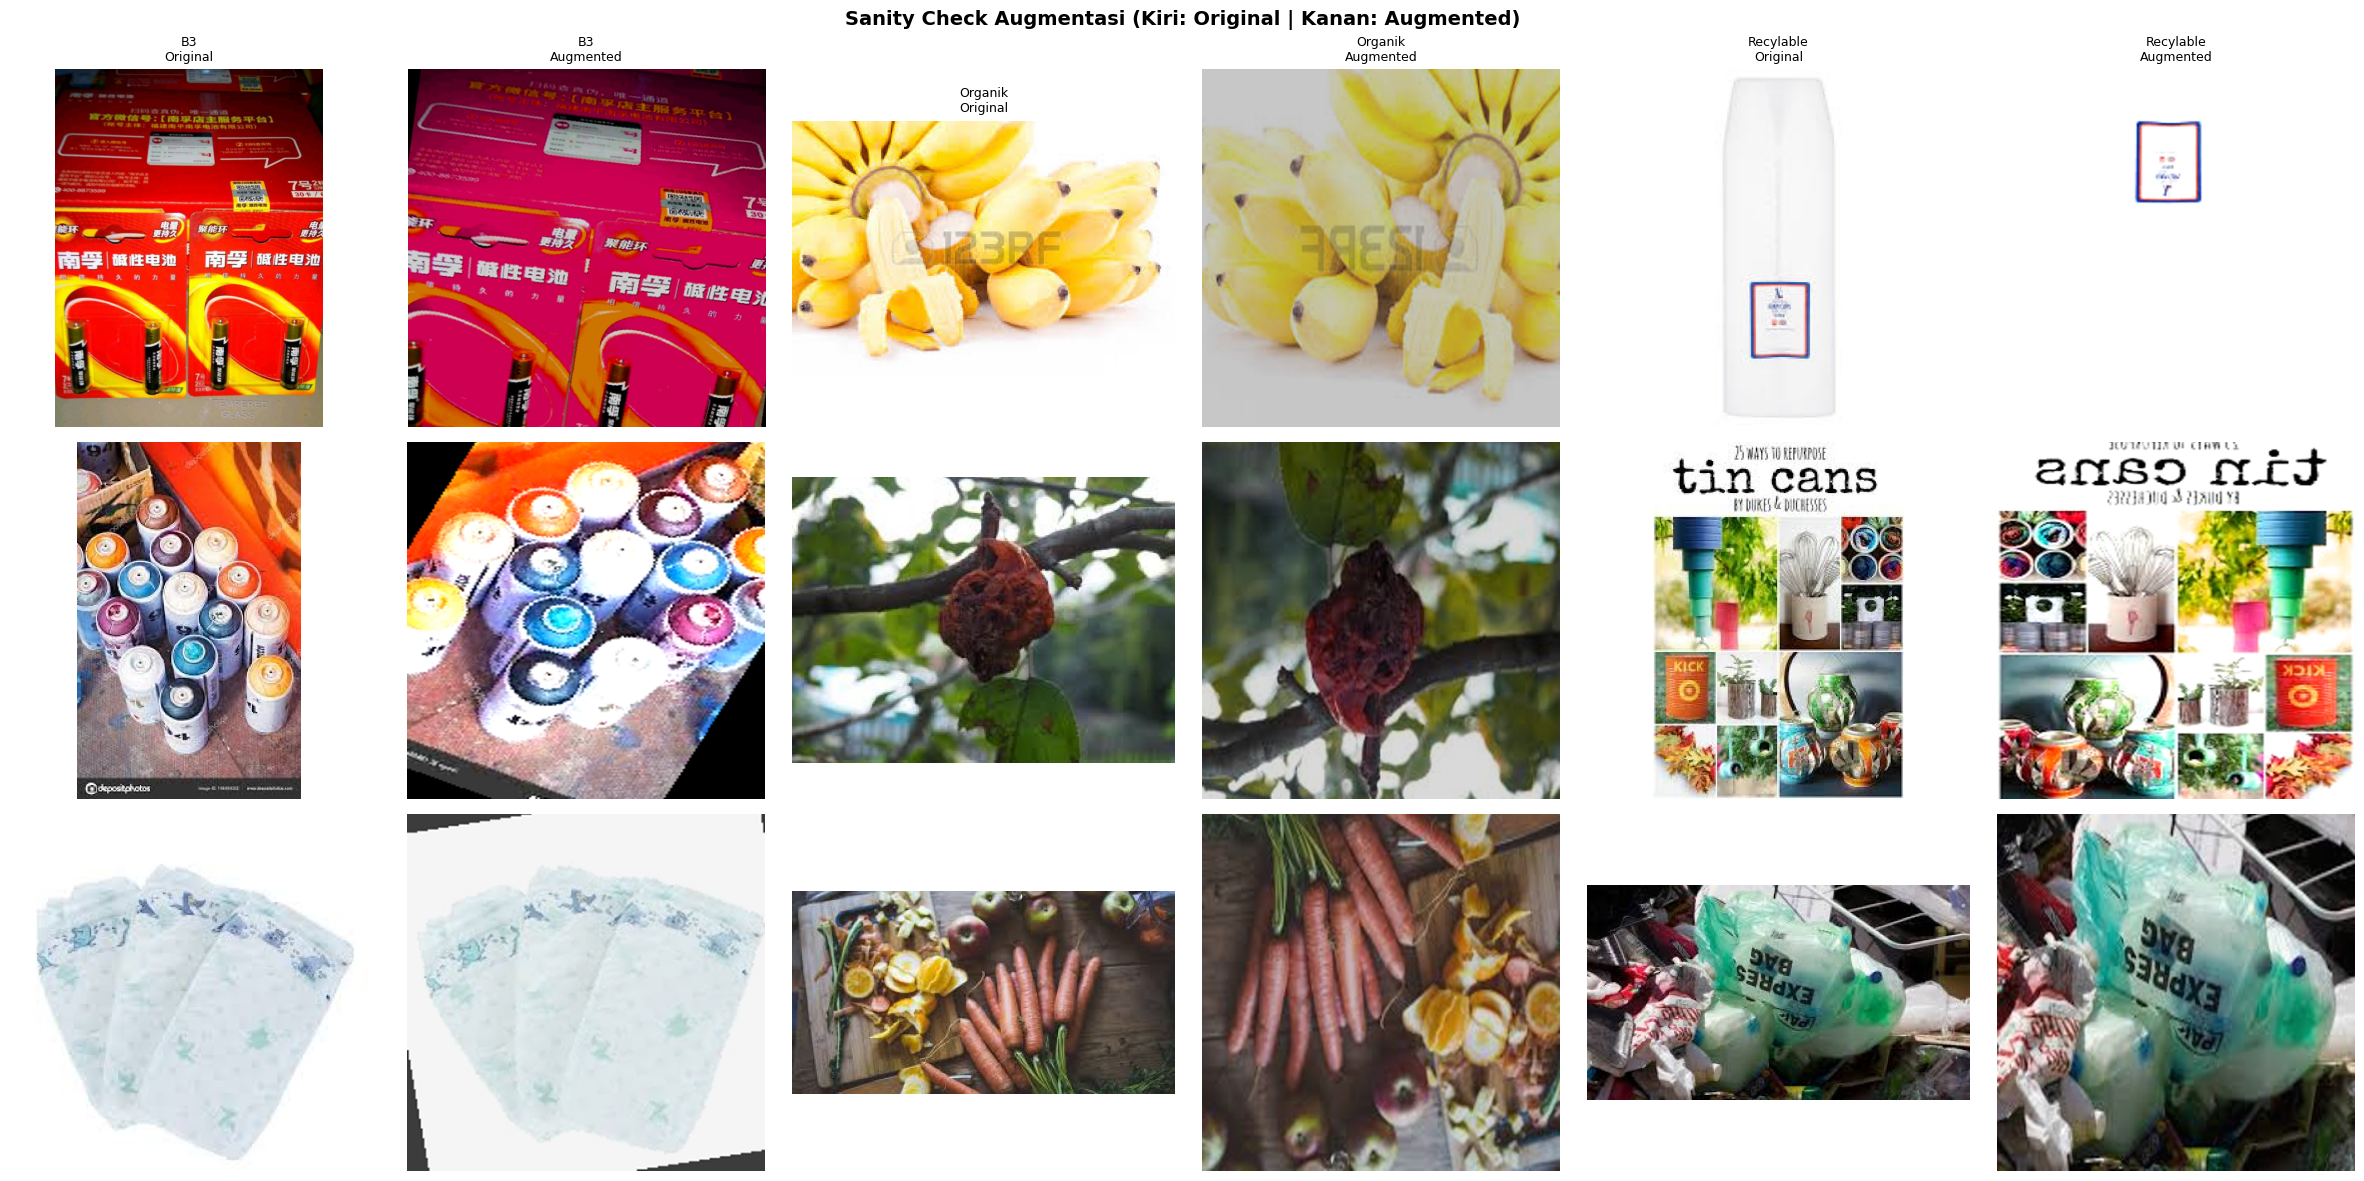

In [8]:
def visualize_augmentations(df: pd.DataFrame, n_per_class: int = 3, save_path: str = None):
    """
    Plot contoh gambar per kelas:
    - Kolom kiri : gambar ASLI (versi bersih yang akan jadi view 0)
    - Kolom kanan: gambar setelah augmentasi train (seperti view 1..N_AUG)
    """
    classes = sorted(df['label'].unique())
    n_cols  = 2 * len(classes)
    fig, axes = plt.subplots(n_per_class, n_cols,
                             figsize=(4 * n_cols, 4 * n_per_class), squeeze=False)
    fig.suptitle('Sanity Check Augmentasi (Kiri: Original | Kanan: Augmented)',
                 fontsize=14, fontweight='bold')

    for col_offset, cls in enumerate(classes):
        pool   = df[df['label'] == cls]
        subset = pool.sample(n=min(n_per_class, len(pool)), random_state=RANDOM_SEED)
        aug_transform = build_aug('train', label=cls)

        for row_idx, (_, sample) in enumerate(subset.iterrows()):
            orig = load_image(sample['abs_path'])
            aug  = aug_transform(orig)

            ax_orig = axes[row_idx][col_offset * 2]
            ax_aug  = axes[row_idx][col_offset * 2 + 1]
            ax_orig.imshow(orig)
            ax_aug.imshow(aug)
            if row_idx == 0:
                ax_orig.set_title(f'{cls}\nOriginal', fontsize=9)
                ax_aug.set_title(f'{cls}\nAugmented', fontsize=9)
            for ax in (ax_orig, ax_aug):
                ax.axis('off')

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=100, bbox_inches='tight')
        print(f'[OK] Visualisasi disimpan: {save_path}')
    plt.show()


visualize_augmentations(df_train, n_per_class=3,
                        save_path=os.path.join(HEAD_DIR, 'augmentation_sanity_check.png'))


---
# TAHAP 1 – Ekstraksi Embedding (dijalankan sekali)

Tiap gambar dibaca **sekali**, lalu dijadikan `1 + N_AUG` view:
view 0 = versi asli (hanya resize), view 1..N_AUG = versi teraugmentasi (hanya untuk split `train`;
kelas B3 memakai augmentasi yang lebih agresif). Val dan test hanya view 0.

Hasil per split disimpan di `EMBEDDING_DIR/embeddings_{split}.npz`:

| key | isi |
|---|---|
| `embeddings` | `float32 [M, 1152]` (pooler_output vision encoder) |
| `labels` | `int32 [M]` |
| `label_names` | `str [M]` |
| `paths` | `str [M]` (path absolut gambar asli) |
| `orig_idx` | `int32 [M]` (indeks baris di CSV; view dari gambar yang sama punya `orig_idx` sama → penting untuk CV agar tidak bocor) |
| `view_idx` | `int8 [M]` (0 = asli, ≥1 = augmentasi) |

Proses ini **aman terhadap disconnect**: hasil disimpan per potongan (`CHUNK_IMAGES` gambar). Kalau sesi putus,
jalankan ulang cell yang sama dan proses melanjutkan dari potongan terakhir. Split yang sudah selesai otomatis dilewati.


## CELL 8 – Definisi: Encoder, Dataset Multi-View, Fungsi Ekstraksi


In [9]:
from transformers import SiglipVisionModel, SiglipImageProcessor

# Hanya butuh mean/std dari processor; resize sudah dilakukan build_aug (selalu keluar 384x384).
_proc = SiglipImageProcessor.from_pretrained(MODEL_CHECKPOINT)
to_tensor_norm = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=_proc.image_mean, std=_proc.image_std),   # SigLIP: mean=std=0.5 -> range [-1, 1]
])
print(f'[OK] Processor: size={_proc.size} | mean={_proc.image_mean} | std={_proc.image_std}')


def load_vision_encoder() -> nn.Module:
    """SigLIP vision tower saja (tanpa text tower), dibekukan, fp16 jika USE_FP16 dan ada GPU."""
    dtype = torch.float16 if (USE_FP16 and device.type == 'cuda') else torch.float32
    m = SiglipVisionModel.from_pretrained(MODEL_CHECKPOINT)
    m = m.to(device=device, dtype=dtype).eval()
    for p in m.parameters():
        p.requires_grad = False
    print(f'[OK] Vision encoder dimuat | dtype={dtype} | device={device}')
    return m


class MultiViewDataset(Dataset):
    """
    Satu gambar dibaca sekali -> (1 + n_aug) view.
    view 0 = asli (resize saja); view 1.. = augmentasi train sesuai kelas.
    Return: (pixel_values [V, 3, H, W], label_idx, index_di_df)
    """
    def __init__(self, df: pd.DataFrame, n_aug: int, label_to_idx: dict):
        self.paths        = df['abs_path'].tolist()
        self.labels       = df['label'].tolist()
        self.n_aug        = n_aug
        self.label_to_idx = label_to_idx
        self.clean_tf     = build_aug('val')

    def __len__(self) -> int:
        return len(self.paths)

    def __getitem__(self, i: int):
        img   = load_image(self.paths[i])
        label = self.labels[i]
        views = [self.clean_tf(img)]
        if self.n_aug > 0:
            aug_tf = build_aug('train', label=label)
            views += [aug_tf(img) for _ in range(self.n_aug)]
        pv = torch.stack([to_tensor_norm(v) for v in views], dim=0)   # [V, 3, H, W]
        return pv, self.label_to_idx[label], i


@torch.no_grad()
def encode_views(vision_model: nn.Module, pv: torch.Tensor) -> np.ndarray:
    """pv: [B, V, 3, H, W] -> numpy float32 [B, V, D] (pooler_output tiap view)."""
    outs = []
    for v in range(pv.shape[1]):
        x   = pv[:, v].to(device=device, dtype=vision_model.dtype, non_blocking=True)
        emb = vision_model(pixel_values=x).pooler_output          # [B, D]
        outs.append(emb.float().cpu())
    return torch.stack(outs, dim=1).numpy()                        # [B, V, D]


# ── Penyimpanan potongan (part) untuk resume ─────────────────
def save_part(parts_dir: str, start: int, emb, orig, view, n_images: int) -> None:
    tmp   = os.path.join(parts_dir, 'tmp_part.npz')       # tulis dulu ke file sementara ...
    final = os.path.join(parts_dir, f'part_{start:07d}.npz')
    np.savez(tmp, embeddings=emb, orig_idx=orig, view_idx=view, n_images=n_images)
    os.replace(tmp, final)                                 # ... lalu ganti nama (atomik) -> tidak ada part setengah jadi


def scan_parts(parts_dir: str, n_total: int) -> int:
    """Hitung berapa gambar asli yang sudah selesai dari part yang ada. Part tidak konsisten -> mulai ulang."""
    part_files = sorted(Path(parts_dir).glob('part_*.npz'))
    n_done = 0
    for pf in part_files:
        start = int(pf.stem.split('_')[1])
        try:
            with np.load(pf) as z:
                n_img = int(z['n_images'])
        except Exception:
            n_img = -1
        if start != n_done or n_img <= 0:
            print('  [WARN] Part tidak konsisten → split ini diproses ulang dari awal.')
            for p in part_files:
                p.unlink()
            return 0
        n_done += n_img
    if n_done > n_total:
        print('  [WARN] Jumlah part melebihi jumlah data (manifest berubah?) → proses ulang dari awal.')
        for p in part_files:
            p.unlink()
        return 0
    return n_done


def assemble_parts(parts_dir: str):
    E, O, V = [], [], []
    for pf in sorted(Path(parts_dir).glob('part_*.npz')):
        with np.load(pf) as z:
            E.append(z['embeddings']); O.append(z['orig_idx']); V.append(z['view_idx'])
    return np.concatenate(E), np.concatenate(O), np.concatenate(V)


def extract_split(df: pd.DataFrame, split_name: str, n_aug: int, vision_model: nn.Module) -> str:
    """Ekstrak embedding satu split -> EMBEDDING_DIR/embeddings_{split}.npz. Lewati jika sudah ada."""
    out_path = os.path.join(EMBEDDING_DIR, f'embeddings_{split_name}.npz')
    if os.path.exists(out_path):
        print(f'[SKIP] {split_name}: sudah ada → {out_path}')
        return out_path

    df        = df.reset_index(drop=True)
    N         = len(df)
    V         = 1 + n_aug
    parts_dir = os.path.join(EMBEDDING_DIR, f'_parts_{split_name}')
    os.makedirs(parts_dir, exist_ok=True)

    n_done = scan_parts(parts_dir, N)
    if n_done:
        print(f'[RESUME] {split_name}: {n_done}/{N} gambar sudah diproses, melanjutkan...')

    if n_done < N:
        ds     = MultiViewDataset(df.iloc[n_done:].reset_index(drop=True), n_aug, LABEL_TO_IDX)
        loader = DataLoader(
            ds, batch_size=BATCH_SIZE_EKSTRAKSI, shuffle=False,
            num_workers=NUM_WORKERS_EKSTRAKSI, pin_memory=(device.type == 'cuda'),
            prefetch_factor=(2 if NUM_WORKERS_EKSTRAKSI > 0 else None),
        )
        buf_e, buf_o, buf_v, buf_n = [], [], [], 0
        chunk_start = n_done

        def flush():
            nonlocal buf_e, buf_o, buf_v, buf_n, chunk_start
            if buf_n == 0:
                return
            save_part(parts_dir, chunk_start,
                      np.concatenate(buf_e), np.concatenate(buf_o), np.concatenate(buf_v), buf_n)
            chunk_start += buf_n
            buf_e, buf_o, buf_v, buf_n = [], [], [], 0

        for pv, _, idx in tqdm(loader, desc=f'Ekstrak [{split_name}]', unit='batch'):
            feats = encode_views(vision_model, pv)                 # [B, V, D]
            B     = feats.shape[0]
            orig  = idx.numpy() + n_done                           # indeks di df penuh
            buf_e.append(feats.reshape(B * V, -1))                 # urutan: gambar0 v0..vV-1, gambar1 v0..
            buf_o.append(np.repeat(orig, V).astype(np.int32))
            buf_v.append(np.tile(np.arange(V), B).astype(np.int8))
            buf_n += B
            if buf_n >= CHUNK_IMAGES:
                flush()
        flush()

    E, O, Vw = assemble_parts(parts_dir)
    assert len(E) == N * V, f'Jumlah baris {len(E)} != {N} x {V}'

    labels      = df['label'].map(LABEL_TO_IDX).to_numpy()[O]
    label_names = df['label'].to_numpy()[O]
    paths       = df['abs_path'].to_numpy()[O]
    np.savez_compressed(
        out_path,
        embeddings  = E.astype(np.float32),
        labels      = labels.astype(np.int32),
        label_names = label_names.astype(str),
        paths       = paths.astype(str),
        orig_idx    = O.astype(np.int32),
        view_idx    = Vw.astype(np.int8),
    )
    for p in Path(parts_dir).glob('*.npz'):
        p.unlink()
    Path(parts_dir).rmdir()
    print(f'[OK] embeddings_{split_name}.npz → shape={E.shape} ({N} gambar x {V} view)')
    return out_path

print('[OK] Fungsi ekstraksi berhasil didefinisikan.')


preprocessor_config.json:   0%|          | 0.00/368 [00:00<?, ?B/s]

[OK] Processor: size=SizeDict(height=384, width=384, longest_edge=None, shortest_edge=None, max_height=None, max_width=None, min_pixels=None, max_pixels=None) | mean=(0.5, 0.5, 0.5) | std=(0.5, 0.5, 0.5)
[OK] Fungsi ekstraksi berhasil didefinisikan.


## CELL 9 – Jalankan Ekstraksi (train → val → test)

Ini bagian yang lama, tetapi hanya perlu dijalankan **sekali**. Kalau sesi terputus, jalankan ulang cell ini
(mount Drive + Cell 2–8 dulu); ekstraksi akan melanjutkan.


In [10]:
vision_model = load_vision_encoder()

for split_name, df_split, n_aug in [
    ('train', df_train, N_AUG),
    ('val',   df_val,   0),
    ('test',  df_test,  0),
]:
    extract_split(df_split, split_name, n_aug, vision_model)

# Catat metadata supaya jelas embedding ini dibuat dengan pengaturan apa
meta = {
    'model_checkpoint': MODEL_CHECKPOINT, 'image_size': IMAGE_SIZE, 'n_aug': N_AUG,
    'fp16': bool(USE_FP16 and device.type == 'cuda'), 'pooling': 'pooler_output',
    'label_to_idx': LABEL_TO_IDX,
    'n_images': {'train': len(df_train), 'val': len(df_val), 'test': len(df_test)},
}
with open(os.path.join(EMBEDDING_DIR, 'meta.json'), 'w') as f:
    json.dump(meta, f, indent=2)

# Backbone tidak dibutuhkan lagi -> bebaskan VRAM
del vision_model
gc.collect()
if device.type == 'cuda':
    torch.cuda.empty_cache()
print('\n[OK] Tahap 1 selesai. Embedding tersimpan di:', EMBEDDING_DIR)


config.json:   0%|          | 0.00/576 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.51GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/448 [00:00<?, ?it/s]

[transformers] SiglipVisionModel LOAD REPORT from: google/siglip-so400m-patch14-384
Key                                                          | Status     |  | 
-------------------------------------------------------------+------------+--+-
text_model.encoder.layers.{0...26}.self_attn.v_proj.bias     | UNEXPECTED |  | 
text_model.encoder.layers.{0...26}.self_attn.q_proj.bias     | UNEXPECTED |  | 
text_model.head.weight                                       | UNEXPECTED |  | 
text_model.encoder.layers.{0...26}.mlp.fc2.bias              | UNEXPECTED |  | 
text_model.encoder.layers.{0...26}.self_attn.out_proj.bias   | UNEXPECTED |  | 
text_model.encoder.layers.{0...26}.layer_norm2.weight        | UNEXPECTED |  | 
text_model.encoder.layers.{0...26}.self_attn.q_proj.weight   | UNEXPECTED |  | 
text_model.encoder.layers.{0...26}.layer_norm1.bias          | UNEXPECTED |  | 
text_model.encoder.layers.{0...26}.mlp.fc1.bias              | UNEXPECTED |  | 
text_model.encoder.layers.{0...26}.s

[OK] Vision encoder dimuat | dtype=torch.float16 | device=cuda
[SKIP] train: sudah ada → /content/drive/MyDrive/Senpro/embeddings/siglip-so400m-patch14-384_naug2/embeddings_train.npz
[SKIP] val: sudah ada → /content/drive/MyDrive/Senpro/embeddings/siglip-so400m-patch14-384_naug2/embeddings_val.npz
[SKIP] test: sudah ada → /content/drive/MyDrive/Senpro/embeddings/siglip-so400m-patch14-384_naug2/embeddings_test.npz

[OK] Tahap 1 selesai. Embedding tersimpan di: /content/drive/MyDrive/Senpro/embeddings/siglip-so400m-patch14-384_naug2


---
# TAHAP 2 – Train Classifier (Head) di Atas Embedding

Bagian ini **tidak memanggil SigLIP sama sekali**. Di sesi baru cukup jalankan Cell 1–4 (mount Drive, config, GPU, import),
lalu cell-cell di bawah (Cell 5–9 tidak perlu).

| Cell | Isi |
|---|---|
| 10 | Load embedding `.npz` |
| 11–12 | Arsitektur head, loss, fungsi training/evaluasi (definisi saja) |
| 13–15 | Train **satu** head sesuai `HEAD_TYPE` → kurva → evaluasi test |
| 16 | Bandingkan head neural (`HEADS_TO_COMPARE`) + kNN cosine |
| 17 | (lambat, opsional) SVM RBF dan LightGBM |
| 18 | Ensemble |
| 19 | Tabel perbandingan (metrik **val**) + evaluasi test untuk pemenang |

Pilih model berdasarkan metrik **val**. Test dipakai sekali di akhir untuk model yang sudah dipilih.


## CELL 10 – Load Embedding `.npz`

- `load_embeddings(split)` → dict: `embeddings`, `labels`, `label_names`, `paths`, `orig_idx`, `view_idx`
- `load_all_embeddings()` → `{'train': {...}, 'val': {...}, 'test': {...}}`
- `normalize=True` → L2-normalize (opsional, untuk cosine similarity / kNN / UMAP)


In [11]:
def _read_npz(path: str, allow_pickle: bool) -> dict:
    with np.load(path, allow_pickle=allow_pickle) as data:
        return {k: data[k] for k in data.files}


def load_embeddings(split: str, embedding_dir: str = None, normalize: bool = False) -> dict:
    """Muat embeddings_{split}.npz dari embedding_dir (default: EMBEDDING_DIR)."""
    embedding_dir = embedding_dir or EMBEDDING_DIR
    path = os.path.join(embedding_dir, f'embeddings_{split}.npz')
    if not os.path.exists(path):
        raise FileNotFoundError(f'{path} tidak ditemukan. Jalankan Tahap 1 (Cell 9) terlebih dulu.')

    try:
        out = _read_npz(path, allow_pickle=False)
    except ValueError:                        # file format lama (object array)
        out = _read_npz(path, allow_pickle=True)
        for k in ('label_names', 'paths'):
            out[k] = out[k].astype(str)

    emb = out['embeddings'].astype(np.float32)
    n   = len(emb)
    assert all(len(out[k]) == n for k in ('labels', 'label_names', 'paths')), \
        f'Panjang array tidak konsisten di {path}'

    if normalize:
        emb = emb / np.clip(np.linalg.norm(emb, axis=1, keepdims=True), 1e-12, None)
    out['embeddings'] = emb
    return out


def load_all_embeddings(splits=('train', 'val', 'test'), **kwargs) -> dict:
    return {s: load_embeddings(s, **kwargs) for s in splits}


emb_data = load_all_embeddings()

print('=== VERIFIKASI EMBEDDING ===')
for split, d in emb_data.items():
    dist = Counter(d['label_names'].tolist())
    n_img = len(np.unique(d['orig_idx'])) if 'orig_idx' in d else '?'
    print(f'\n  [{split}] embeddings={d["embeddings"].shape} dtype={d["embeddings"].dtype}'
          f' | gambar asli={n_img}')
    print(f'    distribusi baris : {dict(sorted(dist.items()))}')
    if 'view_idx' in d:
        print(f'    view             : {dict(sorted(Counter(d["view_idx"].tolist()).items()))}')


=== VERIFIKASI EMBEDDING ===

  [train] embeddings=(63321, 1152) dtype=float32 | gambar asli=21107
    distribusi baris : {'B3': 7278, 'Organik': 28860, 'Recylable': 27183}
    view             : {0: 21107, 1: 21107, 2: 21107}

  [val] embeddings=(4523, 1152) dtype=float32 | gambar asli=4523
    distribusi baris : {'B3': 520, 'Organik': 2062, 'Recylable': 1941}
    view             : {0: 4523}

  [test] embeddings=(4524, 1152) dtype=float32 | gambar asli=4524
    distribusi baris : {'B3': 520, 'Organik': 2062, 'Recylable': 1942}
    view             : {0: 4524}


---
## CELL 11 – Class Weights & Arsitektur Head

`HEAD_TYPE` / `HEADS_TO_COMPARE` menerima:

| nama | bentuk |
|---|---|
| `linear` | 1152 → 3 (linear probe, baseline) |
| `mlp` | 1152 → 576 → 3, aktivasi + Dropout |
| `mlp_norm` | 1152 → 576 → **RMSNorm** → aktivasi → Dropout → 3 |
| `mlp2` | 1152 → 512 → 128 → 3 (2 tahap / bottleneck, tiap tahap: RMSNorm + aktivasi + Dropout) |
| `resmlp` | proyeksi 256 + 2 blok residual pre-norm (RMSNorm → Linear → aktivasi → Dropout → Linear) → 3 |

Aktivasi diatur `HEAD_ACT` (`gelu` atau `silu`).


In [12]:
import time

# ── Class weights (dari preprocessing) ────────────────────────
with open(CW_JSON) as f:
    class_weights_dict = json.load(f)

cw_tensor = torch.tensor(
    [class_weights_dict[lbl] for lbl in sorted(LABEL_TO_IDX, key=LABEL_TO_IDX.get)],
    dtype=torch.float32,
).to(device)
print('=== CLASS WEIGHTS ===')
for lbl, w in class_weights_dict.items():
    print(f'  {lbl}: {w:.4f}')
print(f'  Tensor (Recylable, Organik, B3): {cw_tensor.tolist()}\n')


# ── Blok arsitektur ────────────────────────────────────────────
class RMSNorm(nn.Module):
    def __init__(self, dim: int, eps: float = 1e-6):
        super().__init__()
        self.eps    = eps
        self.weight = nn.Parameter(torch.ones(dim))

    def forward(self, x):
        return x * torch.rsqrt(x.pow(2).mean(-1, keepdim=True) + self.eps) * self.weight


def make_act(name: str) -> nn.Module:
    return nn.SiLU() if name == 'silu' else nn.GELU()


class ResBlock(nn.Module):
    """Pre-norm residual: x + Linear(Dropout(act(Linear(RMSNorm(x)))))"""
    def __init__(self, width: int, dropout: float, act: str):
        super().__init__()
        self.norm = RMSNorm(width)
        self.fc1  = nn.Linear(width, 2 * width)
        self.act  = make_act(act)
        self.drop = nn.Dropout(dropout)
        self.fc2  = nn.Linear(2 * width, width)

    def forward(self, x):
        return x + self.fc2(self.drop(self.act(self.fc1(self.norm(x)))))


class ResMLPHead(nn.Module):
    def __init__(self, in_dim, num_classes, dropout=0.3, act='gelu', width=256, n_blocks=2):
        super().__init__()
        self.proj   = nn.Linear(in_dim, width)
        self.blocks = nn.Sequential(*[ResBlock(width, dropout, act) for _ in range(n_blocks)])
        self.norm   = RMSNorm(width)
        self.out    = nn.Linear(width, num_classes)

    def forward(self, x):
        return self.out(self.norm(self.blocks(self.proj(x))))


HEAD_TYPES = ('linear', 'mlp', 'mlp_norm', 'mlp2', 'resmlp')


def build_head(head_type: str, in_dim: int, num_classes: int,
               dropout: float = 0.3, act: str = 'gelu') -> nn.Module:
    if head_type == 'linear':
        m = nn.Linear(in_dim, num_classes)
    elif head_type == 'mlp':
        h = in_dim // 2
        m = nn.Sequential(nn.Linear(in_dim, h), make_act(act), nn.Dropout(dropout),
                          nn.Linear(h, num_classes))
    elif head_type == 'mlp_norm':
        h = in_dim // 2
        m = nn.Sequential(nn.Linear(in_dim, h), RMSNorm(h), make_act(act), nn.Dropout(dropout),
                          nn.Linear(h, num_classes))
    elif head_type == 'mlp2':
        m = nn.Sequential(nn.Linear(in_dim, 512), RMSNorm(512), make_act(act), nn.Dropout(dropout),
                          nn.Linear(512, 128),    RMSNorm(128), make_act(act), nn.Dropout(dropout),
                          nn.Linear(128, num_classes))
    elif head_type == 'resmlp':
        m = ResMLPHead(in_dim, num_classes, dropout, act)
    else:
        raise ValueError(f'head_type tidak dikenal: {head_type!r}. Pilih salah satu dari {HEAD_TYPES}')

    for mod in m.modules():
        if isinstance(mod, nn.Linear):
            nn.init.xavier_uniform_(mod.weight)
            nn.init.zeros_(mod.bias)
    return m


class FocalLoss(nn.Module):
    """FL(pt) = -alpha_t * (1 - pt)^gamma * log(pt). Alternatif CrossEntropy."""
    def __init__(self, weight: torch.Tensor = None, gamma: float = 2.0):
        super().__init__()
        self.gamma  = gamma
        self.weight = weight

    def forward(self, logits, targets):
        ce = F.cross_entropy(logits, targets, weight=self.weight, reduction='none')
        pt = torch.exp(-ce)
        return ((1 - pt) ** self.gamma * ce).mean()


def make_criterion() -> nn.Module:
    return (FocalLoss(weight=cw_tensor, gamma=FOCAL_GAMMA) if USE_FOCAL_LOSS
            else nn.CrossEntropyLoss(weight=cw_tensor))


# ── Normalisasi input (statistik dihitung dari TRAIN saja) ────
def fit_input_norm(X_train: np.ndarray, mode: str) -> dict:
    if mode == 'standardize':
        return {'mode': mode,
                'mu': X_train.mean(0).astype(np.float32),
                'sd': (X_train.std(0) + 1e-6).astype(np.float32)}
    return {'mode': mode}


def apply_input_norm(X: np.ndarray, norm: dict) -> np.ndarray:
    X = X.astype(np.float32)
    if norm['mode'] == 'l2':
        X = X / np.clip(np.linalg.norm(X, axis=1, keepdims=True), 1e-12, None)
    elif norm['mode'] == 'standardize':
        X = (X - norm['mu']) / norm['sd']
    return X


print(f'[OK] Arsitektur head: {HEAD_TYPES} | aktivasi: {HEAD_ACT}')


=== CLASS WEIGHTS ===
  Organik: 0.7313
  Recylable: 0.7765
  B3: 2.9000
  Tensor (Recylable, Organik, B3): [0.7765250205993652, 0.7313249707221985, 2.8999810218811035]

[OK] Arsitektur head: ('linear', 'mlp', 'mlp_norm', 'mlp2', 'resmlp') | aktivasi: gelu


---
## CELL 12 – Data ke GPU, Fungsi Training/Evaluasi, Registry Hasil


In [13]:
set_seed(RANDOM_SEED)

# ── Data: normalisasi lalu pindahkan ke GPU ────────────────────
norm = fit_input_norm(emb_data['train']['embeddings'], INPUT_NORM)

def to_dev(split):
    X = torch.from_numpy(apply_input_norm(emb_data[split]['embeddings'], norm)).to(device)
    y = torch.from_numpy(emb_data[split]['labels'].astype(np.int64)).to(device)
    return X, y

X_tr, y_tr = to_dev('train')
X_va, y_va = to_dev('val')
X_te, y_te = to_dev('test')
D = X_tr.shape[1]
print(f'[INFO] Train {tuple(X_tr.shape)} | Val {tuple(X_va.shape)} | Test {tuple(X_te.shape)} | input_norm={INPUT_NORM}')


# ── Path history / checkpoint per run ──────────────────────────
def head_paths(run_name: str):
    return (os.path.join(HEAD_DIR, f'history_{run_name}.json'),
            os.path.join(HEAD_DIR, f'best_head_{run_name}.pt'))

def save_history(history: dict, path: str) -> None:
    with open(path, 'w') as f:
        json.dump(history, f, indent=2)

def load_history(path: str) -> dict:
    with open(path) as f:
        return json.load(f)

def save_head(model, path: str, head_type: str) -> None:
    torch.save({
        'state_dict': model.state_dict(),
        'head_type': head_type, 'in_dim': D, 'num_classes': NUM_CLASSES,
        'dropout': DROPOUT_RATE, 'act': HEAD_ACT,
        'input_norm': {k: (torch.from_numpy(v) if isinstance(v, np.ndarray) else v) for k, v in norm.items()},
        'label_to_idx': LABEL_TO_IDX, 'model_checkpoint': MODEL_CHECKPOINT,
    }, path)

def load_head(path: str):
    """Muat head dari file .pt (arsitektur dibangun ulang dari metadata). Return (model, ckpt)."""
    ckpt = torch.load(path, map_location=device)
    m = build_head(ckpt['head_type'], ckpt['in_dim'], ckpt['num_classes'],
                   ckpt['dropout'], ckpt['act']).to(device)
    m.load_state_dict(ckpt['state_dict'])
    return m.eval(), ckpt


# ── Metrik ─────────────────────────────────────────────────────
def metrics_from_preds(y_true: np.ndarray, y_pred: np.ndarray) -> dict:
    p, r, f, _ = precision_recall_fscore_support(
        y_true, y_pred, labels=list(range(NUM_CLASSES)), zero_division=0)
    out = {'acc': float((y_true == y_pred).mean()), 'macro_f1': float(f.mean())}
    for i in range(NUM_CLASSES):
        n = IDX_TO_LABEL[i]
        out[f'precision_{n}'], out[f'recall_{n}'], out[f'f1_{n}'] = float(p[i]), float(r[i]), float(f[i])
    return out


@torch.no_grad()
def predict_proba(model, X, batch_size: int = 4096) -> np.ndarray:
    model.eval()
    return torch.cat([torch.softmax(model(X[i:i + batch_size]), -1)
                      for i in range(0, len(X), batch_size)]).cpu().numpy()


@torch.no_grad()
def evaluate_head(model, X, y, criterion, batch_size=2048, return_preds=False):
    """loss + accuracy + precision/recall/F1 per kelas (dipakai untuk early stopping & history)."""
    model.eval()
    total_loss, all_preds = 0.0, []
    for i in range(0, len(X), batch_size):
        xb, yb = X[i:i + batch_size], y[i:i + batch_size]
        logits = model(xb)
        total_loss += criterion(logits, yb).item() * len(xb)
        all_preds.append(logits.argmax(-1).cpu())
    preds  = torch.cat(all_preds).numpy()
    labels = y.cpu().numpy()

    m = metrics_from_preds(labels, preds)
    metrics = {'loss': total_loss / len(X), 'accuracy': m['acc']}
    for i in range(NUM_CLASSES):
        n = IDX_TO_LABEL[i]
        metrics[f'precision_{n}'] = round(m[f'precision_{n}'], 4)
        metrics[f'recall_{n}']    = round(m[f'recall_{n}'],    4)
        metrics[f'f1_{n}']        = round(m[f'f1_{n}'],        4)
    return (metrics, preds, labels) if return_preds else metrics


# ── Training ───────────────────────────────────────────────────
def train_one_epoch_head(model, X, y, optimizer, criterion, batch_size):
    model.train()
    perm       = torch.randperm(len(X), device=X.device)
    total_loss = torch.zeros((), device=X.device)
    correct    = torch.zeros((), device=X.device)
    for i in range(0, len(X), batch_size):
        idx    = perm[i:i + batch_size]
        xb, yb = X[idx], y[idx]
        optimizer.zero_grad(set_to_none=True)
        logits = model(xb)
        loss   = criterion(logits, yb)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        total_loss += loss.detach() * len(idx)
        correct    += (logits.argmax(-1) == yb).sum()
    return total_loss.item() / len(X), correct.item() / len(X)


def train_head(head_type: str, run_name: str, seed: int = None, verbose: bool = True) -> dict:
    """
    Train satu head dengan early stopping (val loss) + history JSON + simpan best head.
    Return dict: model (bobot terbaik), history, best_epoch, best_val_loss, params, seconds.
    """
    seed = RANDOM_SEED if seed is None else seed
    set_seed(seed)
    t0 = time.time()

    model     = build_head(head_type, D, NUM_CLASSES, DROPOUT_RATE, HEAD_ACT).to(device)
    criterion = make_criterion()
    optimizer = torch.optim.AdamW(model.parameters(), lr=HEAD_LR, weight_decay=HEAD_WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=HEAD_EPOCHS, eta_min=1e-6)
    n_params  = sum(p.numel() for p in model.parameters())
    hist_path, best_path = head_paths(run_name)

    history = {
        'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': [],
        'val_recall_B3': [], 'val_precision_B3': [], 'val_f1_B3': [],
        'val_recall_Recylable': [], 'val_recall_Organik': [],
    }
    best_val_loss, best_epoch, no_improve = float('inf'), -1, 0

    if verbose:
        print(f'Head: {head_type} | act={HEAD_ACT} | params={n_params:,} | max {HEAD_EPOCHS} epoch | '
              f'batch={HEAD_BATCH_SIZE} | patience={EARLY_STOP_PATIENCE}')
        print('=' * 78)

    for epoch in range(HEAD_EPOCHS):
        tr_loss, tr_acc = train_one_epoch_head(model, X_tr, y_tr, optimizer, criterion, HEAD_BATCH_SIZE)
        vm = evaluate_head(model, X_va, y_va, criterion)
        scheduler.step()

        history['train_loss'].append(round(tr_loss, 6));  history['train_acc'].append(round(tr_acc, 6))
        history['val_loss'].append(round(vm['loss'], 6)); history['val_acc'].append(round(vm['accuracy'], 6))
        history['val_recall_B3'].append(vm['recall_B3'])
        history['val_precision_B3'].append(vm['precision_B3'])
        history['val_f1_B3'].append(vm['f1_B3'])
        history['val_recall_Recylable'].append(vm['recall_Recylable'])
        history['val_recall_Organik'].append(vm['recall_Organik'])

        improved = vm['loss'] < best_val_loss
        if verbose:
            print(f'Ep {epoch+1:02d}/{HEAD_EPOCHS} | train loss {tr_loss:.4f} acc {tr_acc*100:5.2f}% | '
                  f'val loss {vm["loss"]:.4f} acc {vm["accuracy"]*100:5.2f}% | '
                  f'recall R/O/B3 {vm["recall_Recylable"]:.3f}/{vm["recall_Organik"]:.3f}/{vm["recall_B3"]:.3f}'
                  f'{"  ★" if improved else ""}')

        if improved:
            best_val_loss, best_epoch, no_improve = vm['loss'], epoch + 1, 0
            save_head(model, best_path, head_type)
            save_history(history, hist_path)
        else:
            no_improve += 1
            if no_improve >= EARLY_STOP_PATIENCE:
                if verbose:
                    print(f'\n[EARLY STOP] val_loss tidak turun selama {EARLY_STOP_PATIENCE} epoch → berhenti di epoch {epoch+1}.')
                break
        if (epoch + 1) % SAVE_EVERY_N_EPOCHS == 0:
            save_history(history, hist_path)

    save_history(history, hist_path)
    model.load_state_dict(torch.load(best_path, map_location=device)['state_dict'])   # kembali ke bobot terbaik
    model.eval()
    seconds = time.time() - t0
    if verbose:
        print(f'\n[OK] Selesai ({seconds:.0f}s). Best val_loss {best_val_loss:.4f} di epoch {best_epoch}')
        print(f'[OK] History : {hist_path}\n[OK] Best head: {best_path}')
    return {'model': model, 'history': history, 'best_epoch': best_epoch,
            'best_val_loss': best_val_loss, 'params': n_params, 'seconds': seconds}


# ── Registry hasil untuk perbandingan (metrik VAL) ─────────────
results = {}

def register_result(name, kind, val_probs=None, test_probs=None,
                    val_pred=None, test_pred=None, seconds=0.0, note=''):
    if val_probs  is not None: val_pred  = val_probs.argmax(1)
    if test_probs is not None: test_pred = test_probs.argmax(1)
    results[name] = {
        'kind': kind, 'val_probs': val_probs, 'test_probs': test_probs,
        'val_pred': val_pred, 'test_pred': test_pred, 'seconds': seconds, 'note': note,
        'val_metrics': metrics_from_preds(y_va.cpu().numpy(), val_pred),
    }

def fmt_params(n: int) -> str:
    return f'{n/1e6:.2f}M' if n >= 1e6 else f'{n/1e3:.1f}K'

def register_neural(name, out):
    m = out['model']
    register_result(name, 'neural', predict_proba(m, X_va), predict_proba(m, X_te),
                    seconds=out['seconds'],
                    note=f'{fmt_params(out["params"])} param, best ep {out["best_epoch"]}')

print('[OK] Fungsi training, evaluasi, dan registry hasil siap.')


[INFO] Train (63321, 1152) | Val (4523, 1152) | Test (4524, 1152) | input_norm=standardize
[OK] Fungsi training, evaluasi, dan registry hasil siap.


---
## CELL 13 – Train **Satu** Head (sesuai `HEAD_TYPE`)

Kalau langsung mau membandingkan semua arsitektur, lewati ke Cell 16.


In [14]:
HISTORY_PATH, BEST_PATH = head_paths(RUN_NAME)

out     = train_head(HEAD_TYPE, RUN_NAME, seed=RANDOM_SEED, verbose=True)
model   = out['model']
history = out['history']


Head: mlp | act=gelu | params=665,859 | max 60 epoch | batch=256 | patience=8
Ep 01/60 | train loss 0.0517 acc 98.18% | val loss 0.0380 acc 98.70% | recall R/O/B3 0.989/0.985/0.989  ★
Ep 02/60 | train loss 0.0096 acc 99.69% | val loss 0.0469 acc 98.74% | recall R/O/B3 0.989/0.986/0.987
Ep 03/60 | train loss 0.0049 acc 99.84% | val loss 0.0482 acc 98.87% | recall R/O/B3 0.991/0.986/0.990
Ep 04/60 | train loss 0.0024 acc 99.93% | val loss 0.0499 acc 98.89% | recall R/O/B3 0.992/0.986/0.990
Ep 05/60 | train loss 0.0041 acc 99.90% | val loss 0.0674 acc 98.70% | recall R/O/B3 0.990/0.984/0.990
Ep 06/60 | train loss 0.0050 acc 99.83% | val loss 0.0809 acc 98.70% | recall R/O/B3 0.993/0.981/0.989
Ep 07/60 | train loss 0.0072 acc 99.78% | val loss 0.0969 acc 98.59% | recall R/O/B3 0.985/0.988/0.983
Ep 08/60 | train loss 0.0061 acc 99.80% | val loss 0.1015 acc 98.67% | recall R/O/B3 0.986/0.986/0.992
Ep 09/60 | train loss 0.0037 acc 99.88% | val loss 0.0939 acc 98.61% | recall R/O/B3 0.990/0.98

---
## CELL 14 – Plot Kurva Training (dari History JSON)


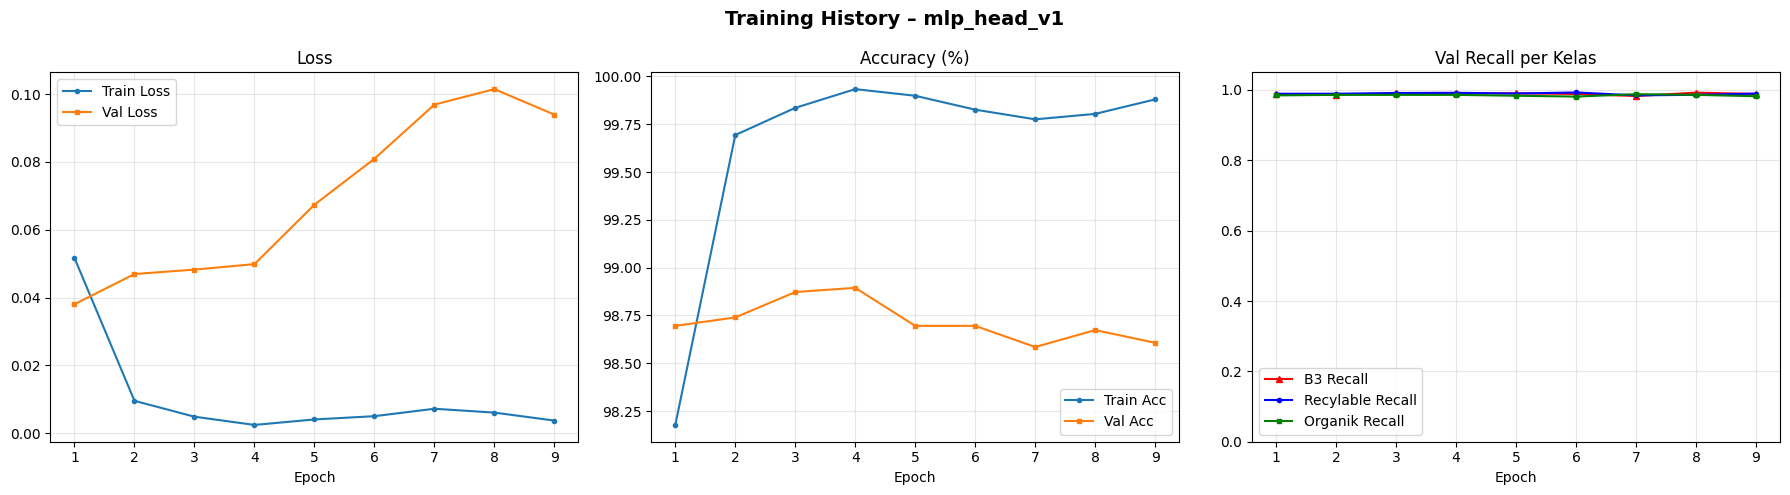

[OK] Kurva disimpan: /content/drive/MyDrive/Senpro/head_runs/training_curves_mlp_head_v1.png


In [15]:
# Membaca dari file JSON di Drive -> bisa dijalankan kapan saja, walau sesi sudah terputus.
# (butuh Cell 2, 4, 11, 12 dijalankan lebih dulu; RUN_NAME menentukan file mana yang dibaca)
HISTORY_PATH, BEST_PATH = head_paths(RUN_NAME)
history = load_history(HISTORY_PATH)
x = range(1, len(history['train_loss']) + 1)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(x, history['train_loss'], label='Train Loss', marker='o', markersize=3)
axes[0].plot(x, history['val_loss'],   label='Val Loss',   marker='s', markersize=3)
axes[0].set_title('Loss'); axes[0].set_xlabel('Epoch'); axes[0].legend(); axes[0].grid(True, alpha=0.3)

axes[1].plot(x, [a*100 for a in history['train_acc']], label='Train Acc', marker='o', markersize=3)
axes[1].plot(x, [a*100 for a in history['val_acc']],   label='Val Acc',   marker='s', markersize=3)
axes[1].set_title('Accuracy (%)'); axes[1].set_xlabel('Epoch'); axes[1].legend(); axes[1].grid(True, alpha=0.3)

axes[2].plot(x, history['val_recall_B3'],        label='B3 Recall',       marker='^', markersize=4, color='red')
axes[2].plot(x, history['val_recall_Recylable'], label='Recylable Recall', marker='o', markersize=3, color='blue')
axes[2].plot(x, history['val_recall_Organik'],   label='Organik Recall',   marker='s', markersize=3, color='green')
axes[2].set_title('Val Recall per Kelas'); axes[2].set_xlabel('Epoch'); axes[2].set_ylim(0, 1.05)
axes[2].legend(); axes[2].grid(True, alpha=0.3)

plt.suptitle(f'Training History – {RUN_NAME}', fontsize=14, fontweight='bold')
plt.tight_layout()
curve_path = os.path.join(HEAD_DIR, f'training_curves_{RUN_NAME}.png')
plt.savefig(curve_path, dpi=120, bbox_inches='tight')
plt.show()
print(f'[OK] Kurva disimpan: {curve_path}')


---
## CELL 15 – Evaluasi Test Set untuk Head dari Cell 13


In [16]:
model, ckpt = load_head(BEST_PATH)
print(f'[OK] Best head ({ckpt["head_type"]}) dimuat dari: {BEST_PATH}')

criterion = make_criterion()
test_metrics, test_preds, test_labels = evaluate_head(model, X_te, y_te, criterion, return_preds=True)
label_names = [IDX_TO_LABEL[i] for i in range(NUM_CLASSES)]

print('\n=== EVALUASI TEST SET ===')
print(f'  Loss    : {test_metrics["loss"]:.4f}')
print(f'  Accuracy: {test_metrics["accuracy"]*100:.2f}%')
print('\n  Per kelas:')
for lname in label_names:
    print(f'    {lname:10s} | P={test_metrics[f"precision_{lname}"]:.4f} '
          f'| R={test_metrics[f"recall_{lname}"]:.4f} '
          f'| F1={test_metrics[f"f1_{lname}"]:.4f}')

print('\n=== CLASSIFICATION REPORT ===')
print(classification_report(test_labels, test_preds, target_names=label_names, zero_division=0))

print('=== CONFUSION MATRIX ===')
print(pd.DataFrame(confusion_matrix(test_labels, test_preds, labels=list(range(NUM_CLASSES))),
                   index=label_names, columns=label_names))


[OK] Best head (mlp) dimuat dari: /content/drive/MyDrive/Senpro/head_runs/best_head_mlp_head_v1.pt

=== EVALUASI TEST SET ===
  Loss    : 0.0357
  Accuracy: 98.81%

  Per kelas:
    Recylable  | P=0.9896 | R=0.9830 | F1=0.9863
    Organik    | P=0.9894 | R=0.9927 | F1=0.9910
    B3         | P=0.9772 | R=0.9885 | F1=0.9828

=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

   Recylable       0.99      0.98      0.99      1942
     Organik       0.99      0.99      0.99      2062
          B3       0.98      0.99      0.98       520

    accuracy                           0.99      4524
   macro avg       0.99      0.99      0.99      4524
weighted avg       0.99      0.99      0.99      4524

=== CONFUSION MATRIX ===
           Recylable  Organik   B3
Recylable       1909       21   12
Organik           15     2047    0
B3                 5        1  514


---
# Perbandingan Arsitektur Head

Semua model di bawah dilatih/dinilai di embedding yang sama. Tabel perbandingan (Cell 19) memakai metrik **val**.
Probabilitas test disimpan di belakang layar, tetapi tidak dipakai untuk memilih model.

## CELL 16 – Head Neural (`HEADS_TO_COMPARE`) + kNN Cosine

Tiap head dilatih dengan early stopping yang sama. kNN cosine dijalankan di GPU: vote tetangga terdekat
berbobot softmax(similarity / `KNN_TEMP`), lalu dikali class weight supaya kelas minoritas tidak kalah suara.


In [17]:
# ── Head neural ────────────────────────────────────────────────
for ht in HEADS_TO_COMPARE:
    print(f'[{ht:9s}] training...', end=' ', flush=True)
    out = train_head(ht, f'{RUN_NAME}__{ht}', seed=RANDOM_SEED, verbose=False)
    register_neural(ht, out)
    m = results[ht]['val_metrics']
    print(f'{out["seconds"]:4.0f}s | best ep {out["best_epoch"]:2d} | '
          f'val macroF1 {m["macro_f1"]:.4f} | recall B3 {m["recall_B3"]:.4f}')


# ── kNN cosine (GPU) ───────────────────────────────────────────
@torch.no_grad()
def knn_probs(Xq, Xdb, ydb, k, temp, class_mult=None, chunk=1024):
    """Xq, Xdb sudah L2-normalized (tensor di device). Return prob numpy [Nq, C]."""
    k = min(k, len(Xdb))
    parts = []
    for i in range(0, len(Xq), chunk):
        sim = Xq[i:i + chunk] @ Xdb.T                              # cosine similarity
        top_s, top_i = sim.topk(k, dim=1)
        w = torch.softmax(top_s / temp, dim=1)                     # bobot tetangga
        votes = torch.zeros(len(top_s), NUM_CLASSES, device=Xq.device)
        votes.scatter_add_(1, ydb[top_i], w)
        parts.append(votes)
    p = torch.cat(parts)
    if class_mult is not None:
        p = p * class_mult
    return (p / p.sum(1, keepdim=True)).cpu().numpy()

def _l2(split):
    x = torch.from_numpy(emb_data[split]['embeddings']).to(device)
    return x / x.norm(dim=1, keepdim=True).clamp_min(1e-12)

t0 = time.time()
Xdb = _l2('train')
register_result(
    'knn_cosine', 'knn',
    val_probs =knn_probs(_l2('val'),  Xdb, y_tr, KNN_K, KNN_TEMP, cw_tensor),
    test_probs=knn_probs(_l2('test'), Xdb, y_tr, KNN_K, KNN_TEMP, cw_tensor),
    seconds=time.time() - t0, note=f'k={KNN_K}, T={KNN_TEMP}, vote x class weight')
del Xdb
if device.type == 'cuda':
    torch.cuda.empty_cache()
m = results['knn_cosine']['val_metrics']
print(f'[knn_cosine] {results["knn_cosine"]["seconds"]:4.0f}s | val macroF1 {m["macro_f1"]:.4f} | recall B3 {m["recall_B3"]:.4f}')


[linear   ] training...    4s | best ep  3 | val macroF1 0.9819 | recall B3 0.9904
[mlp      ] training...    5s | best ep  1 | val macroF1 0.9864 | recall B3 0.9885
[mlp_norm ] training...    5s | best ep  1 | val macroF1 0.9876 | recall B3 0.9885
[mlp2     ] training...    7s | best ep  1 | val macroF1 0.9865 | recall B3 0.9865
[resmlp   ] training...   10s | best ep  1 | val macroF1 0.9847 | recall B3 0.9865
[knn_cosine]    1s | val macroF1 0.9892 | recall B3 0.9942


---
## CELL 17 – (Lambat, Opsional) SVM RBF dan LightGBM

Berjalan di **CPU** (Colab gratis: 2 core), jadi paling lama di antara semua model. Matikan salah satunya dengan
`RUN_SVM = False` / `RUN_LGBM = False`.

- **SVM RBF** dilatih hanya pada baris *view asli* (tanpa augmentasi), karena SVM RBF melambat drastis seiring jumlah baris.
  Kalau masih terlalu lama, isi `SVM_MAX_ROWS` di Cell 2 (mis. 8000).
- **LightGBM** memakai semua baris, early stopping pada val, `class_weight='balanced'`.


In [18]:
RUN_SVM  = True
RUN_LGBM = True

ytr_np, yva_np = emb_data['train']['labels'], emb_data['val']['labels']

# ── SVM RBF ────────────────────────────────────────────────────
if RUN_SVM:
    try:
        from sklearn.svm import SVC
        from sklearn.model_selection import train_test_split

        view  = emb_data['train'].get('view_idx')
        mask0 = (view == 0) if view is not None else np.ones(len(ytr_np), dtype=bool)
        Xs = apply_input_norm(emb_data['train']['embeddings'][mask0], norm)
        ys = ytr_np[mask0]
        if SVM_MAX_ROWS and len(Xs) > SVM_MAX_ROWS:
            Xs, _, ys, _ = train_test_split(Xs, ys, train_size=SVM_MAX_ROWS,
                                            stratify=ys, random_state=RANDOM_SEED)
        print(f'[svm_rbf] training pada {len(Xs)} baris... (bisa lama)', flush=True)
        t0  = time.time()
        svm = SVC(kernel='rbf', C=SVM_C, gamma='scale', class_weight='balanced').fit(Xs, ys)
        register_result(
            'svm_rbf', 'sklearn',
            val_pred =svm.predict(apply_input_norm(emb_data['val']['embeddings'],  norm)),
            test_pred=svm.predict(apply_input_norm(emb_data['test']['embeddings'], norm)),
            seconds=time.time() - t0, note=f'C={SVM_C}, {len(Xs)} baris view asli')
        m = results['svm_rbf']['val_metrics']
        print(f'[svm_rbf] {results["svm_rbf"]["seconds"]:.0f}s | val macroF1 {m["macro_f1"]:.4f} | recall B3 {m["recall_B3"]:.4f}')
        del Xs, ys, svm
    except Exception as e:
        print(f'[svm_rbf] GAGAL: {type(e).__name__}: {e}')

# ── LightGBM ───────────────────────────────────────────────────
if RUN_LGBM:
    try:
        try:
            import lightgbm as lgb
        except ImportError:
            import subprocess, sys
            subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'lightgbm'], check=True)
            import lightgbm as lgb

        Xtr_raw, Xva_raw, Xte_raw = (emb_data[s]['embeddings'] for s in ('train', 'val', 'test'))
        print(f'[lightgbm] training pada {len(Xtr_raw)} baris... (bisa lama)', flush=True)
        t0  = time.time()
        clf = lgb.LGBMClassifier(
            n_estimators=LGBM_MAX_TREES, learning_rate=0.05, num_leaves=31,
            colsample_bytree=0.3, subsample=0.8, subsample_freq=1,
            class_weight='balanced', n_jobs=-1, verbose=-1, random_state=RANDOM_SEED)
        clf.fit(Xtr_raw, ytr_np, eval_set=[(Xva_raw, yva_np)],
                callbacks=[lgb.early_stopping(30, verbose=False)])
        register_result(
            'lightgbm', 'sklearn',
            val_probs=clf.predict_proba(Xva_raw), test_probs=clf.predict_proba(Xte_raw),
            seconds=time.time() - t0, note=f'{getattr(clf, "best_iteration_", None)} pohon')
        m = results['lightgbm']['val_metrics']
        print(f'[lightgbm] {results["lightgbm"]["seconds"]:.0f}s | val macroF1 {m["macro_f1"]:.4f} | recall B3 {m["recall_B3"]:.4f}')
        del clf
    except Exception as e:
        print(f'[lightgbm] GAGAL: {type(e).__name__}: {e}')


[svm_rbf] training pada 21107 baris... (bisa lama)
[svm_rbf] 111s | val macroF1 0.9894 | recall B3 0.9923
[lightgbm] training pada 63321 baris... (bisa lama)


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[lightgbm] 206s | val macroF1 0.9836 | recall B3 0.9750


---
## CELL 18 – Ensemble

Rata-rata **probabilitas (softmax)**, bukan logit mentah, supaya head yang skalanya berbeda tetap sebanding.

- `ens_semua_head` : rata-rata semua head neural dari Cell 16.
- `ens_seed_<head>` : head neural terbaik (macro F1 val) dilatih ulang dengan beberapa seed (`ENSEMBLE_SEEDS`), lalu dirata-rata.


In [19]:
neural = [n for n in HEADS_TO_COMPARE if n in results and results[n]['kind'] == 'neural']
assert neural, 'Belum ada head neural di registry. Jalankan Cell 16 dulu.'

# (a) rata-rata semua head neural
register_result(
    'ens_semua_head', 'ensemble',
    val_probs =np.mean([results[n]['val_probs']  for n in neural], axis=0),
    test_probs=np.mean([results[n]['test_probs'] for n in neural], axis=0),
    note=f'rata-rata prob {len(neural)} head')

# (b) beberapa seed dari head neural terbaik
best_type = max(neural, key=lambda n: results[n]['val_metrics']['macro_f1'])
mem_val, mem_test, t0 = [results[best_type]['val_probs']], [results[best_type]['test_probs']], time.time()
print(f'[ens_seed] head terbaik: {best_type}')
for s in ENSEMBLE_SEEDS:
    if s == RANDOM_SEED:          # seed ini sudah dilatih di Cell 16
        continue
    print(f'  seed {s}...', end=' ', flush=True)
    out = train_head(best_type, f'{RUN_NAME}__{best_type}_s{s}', seed=s, verbose=False)
    mem_val.append(predict_proba(out['model'], X_va)); mem_test.append(predict_proba(out['model'], X_te))
    print(f'{out["seconds"]:.0f}s')

register_result(f'ens_seed_{best_type}', 'ensemble',
                val_probs=np.mean(mem_val, axis=0), test_probs=np.mean(mem_test, axis=0),
                seconds=time.time() - t0, note=f'{len(mem_val)} seed')
for n in ('ens_semua_head', f'ens_seed_{best_type}'):
    m = results[n]['val_metrics']
    print(f'[{n}] val macroF1 {m["macro_f1"]:.4f} | recall B3 {m["recall_B3"]:.4f}')


[ens_seed] head terbaik: mlp_norm
  seed 43... 6s
  seed 44... 5s
  seed 45... 6s
  seed 46... 5s
[ens_semua_head] val macroF1 0.9879 | recall B3 0.9904
[ens_seed_mlp_norm] val macroF1 0.9898 | recall B3 0.9962


---
## CELL 19 – Tabel Perbandingan (Val) + Evaluasi Test untuk Pemenang

Kolom: akurasi, macro F1, recall tiap kelas, precision dan F1 B3, waktu (detik). Urut dari macro F1 val tertinggi.
Kalau recall B3 lebih penting bagi Anda daripada macro F1, pilih dari kolom `recall_B3` (cek juga `prec_B3`, supaya
recall tinggi tidak dibeli dengan banyak salah alarm).

Setelah memilih, jalankan `report_test('nama_model')` sekali untuk melihat hasil di test.


,model,tipe,acc,macro_F1,recall_Recylable,recall_Organik,recall_B3,prec_B3,F1_B3,detik,catatan
0,ens_seed_mlp_norm,ensemble,0.9889,0.9898,0.9907,0.9855,0.9962,0.9885,0.9923,23,5 seed
1,svm_rbf,sklearn,0.9885,0.9894,0.9907,0.9855,0.9923,0.9923,0.9923,111,"C=1.0, 21107 baris view asli"
2,knn_cosine,knn,0.9892,0.9892,0.9902,0.9869,0.9942,0.9848,0.9895,1,"k=15, T=0.05, vote x class weight"
3,ens_semua_head,ensemble,0.9883,0.9879,0.9912,0.9850,0.9904,0.9828,0.9866,0,rata-rata prob 5 head
4,mlp_norm,neural,0.9876,0.9876,0.9897,0.9855,0.9885,0.9866,0.9875,5,"666.4K param, best ep 1"
5,mlp2,neural,0.9872,0.9865,0.9912,0.9835,0.9865,0.9828,0.9846,7,"657.0K param, best ep 1"
6,mlp,neural,0.9870,0.9864,0.9892,0.9845,0.9885,0.9809,0.9847,5,"665.9K param, best ep 1"
7,resmlp,neural,0.9841,0.9847,0.9820,0.9855,0.9865,0.9865,0.9865,10,"822.5K param, best ep 1"
8,lightgbm,sklearn,0.9843,0.9836,0.9871,0.9840,0.9750,0.9883,0.9816,206,400 pohon
9,linear,neural,0.9832,0.9819,0.9845,0.9801,0.9904,0.9662,0.9782,4,"3.5K param, best ep 3"


[OK] Tabel disimpan: /content/drive/MyDrive/Senpro/head_runs/perbandingan_head_mlp_head_v1.csv

macro F1 val tertinggi : ens_seed_mlp_norm
recall B3 val tertinggi: ens_seed_mlp_norm


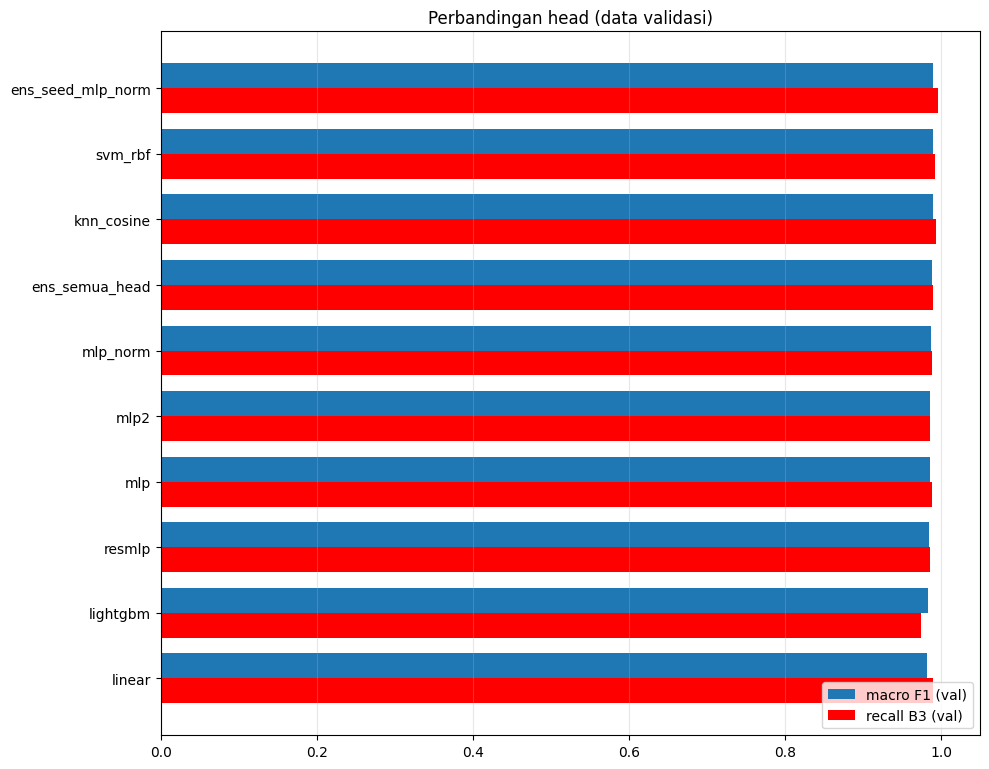

=== TEST: ens_seed_mlp_norm ===
              precision    recall  f1-score   support

   Recylable       0.99      0.99      0.99      1942
     Organik       0.99      0.99      0.99      2062
          B3       0.99      0.99      0.99       520

    accuracy                           0.99      4524
   macro avg       0.99      0.99      0.99      4524
weighted avg       0.99      0.99      0.99      4524

           Recylable  Organik   B3
Recylable       1922       13    7
Organik           15     2047    0
B3                 7        0  513


In [20]:
from IPython.display import display

def comparison_table() -> pd.DataFrame:
    rows = []
    for name, r in results.items():
        m = r['val_metrics']
        rows.append({
            'model': name, 'tipe': r['kind'],
            'acc': m['acc'], 'macro_F1': m['macro_f1'],
            'recall_Recylable': m['recall_Recylable'], 'recall_Organik': m['recall_Organik'],
            'recall_B3': m['recall_B3'], 'prec_B3': m['precision_B3'], 'F1_B3': m['f1_B3'],
            'detik': round(r['seconds']), 'catatan': r['note'],
        })
    return pd.DataFrame(rows).sort_values('macro_F1', ascending=False).reset_index(drop=True)


def report_test(name: str) -> None:
    r, y = results[name], y_te.cpu().numpy()
    names = [IDX_TO_LABEL[i] for i in range(NUM_CLASSES)]
    print(f'=== TEST: {name} ===')
    print(classification_report(y, r['test_pred'], target_names=names, zero_division=0))
    print(pd.DataFrame(confusion_matrix(y, r['test_pred'], labels=list(range(NUM_CLASSES))),
                       index=names, columns=names))


df_cmp = comparison_table()
display(df_cmp.round(4))
csv_path = os.path.join(HEAD_DIR, f'perbandingan_head_{RUN_NAME}.csv')
df_cmp.to_csv(csv_path, index=False)
print(f'[OK] Tabel disimpan: {csv_path}')

best_f1 = df_cmp.iloc[0]['model']
best_b3 = df_cmp.loc[df_cmp['recall_B3'].idxmax(), 'model']
print(f'\nmacro F1 val tertinggi : {best_f1}')
print(f'recall B3 val tertinggi: {best_b3}')

# Grafik: macro F1 vs recall B3 (val)
fig, ax = plt.subplots(figsize=(10, 0.6 * len(df_cmp) + 1.8))
ypos, h = np.arange(len(df_cmp)), 0.38
ax.barh(ypos - h/2, df_cmp['macro_F1'],  h, label='macro F1 (val)')
ax.barh(ypos + h/2, df_cmp['recall_B3'], h, label='recall B3 (val)', color='red')
ax.set_yticks(ypos); ax.set_yticklabels(df_cmp['model']); ax.invert_yaxis()
ax.set_xlim(0, 1.05); ax.grid(axis='x', alpha=0.3); ax.legend(loc='lower right')
ax.set_title('Perbandingan head (data validasi)')
plt.tight_layout()
plt.savefig(os.path.join(HEAD_DIR, f'perbandingan_head_{RUN_NAME}.png'), dpi=120, bbox_inches='tight')
plt.show()

# Evaluasi test SEKALI untuk pemenang macro F1 (ganti nama kalau memilih berdasarkan kriteria lain)
report_test(best_f1)
